dict_keys(['operation', 'start_datetime', 'end_datetime', 'mu', 'sigma', 'sample_hz', 'timeout', 'extra', 'samples', 'outcome'])
operation: load_first_bloc
outcome: success
mu: 0.005333333333333333
sigma: 0.3388086144987526
n_samples: 73


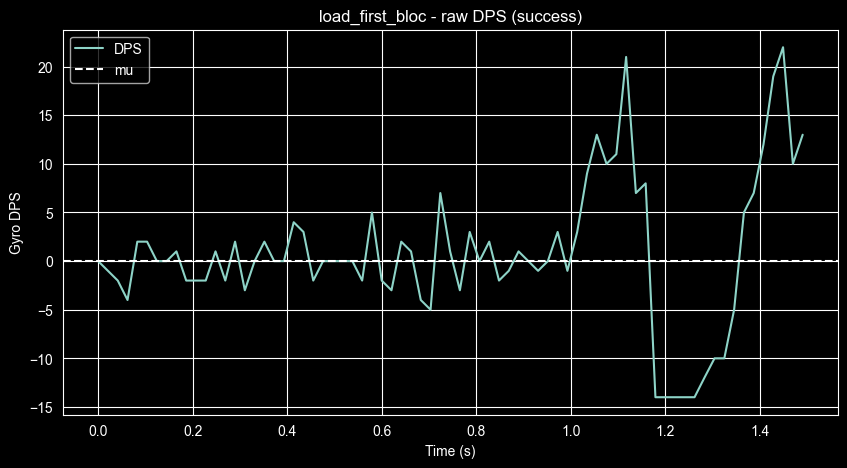

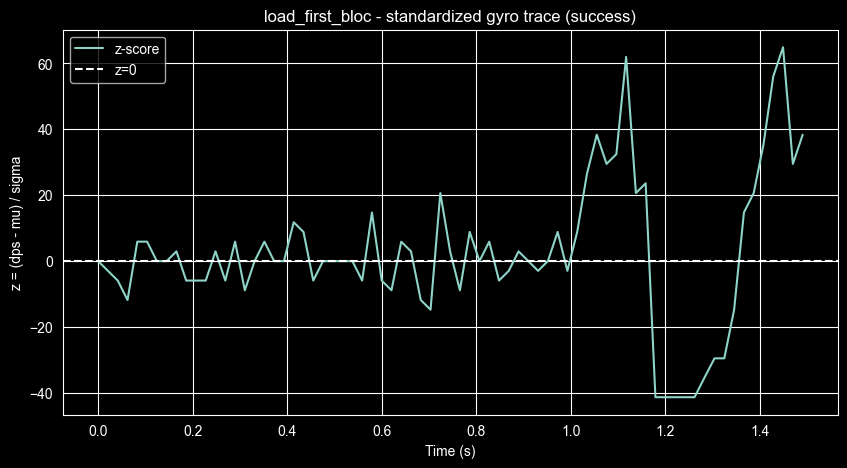

In [4]:
import pickle
import matplotlib.pyplot as plt
import os

for file in os.listdir("."):
    #if file.endswith(".pkl"):
    if file == "load_first_bloc_20260324_003016.pkl": # loading failed
        with open(file, "rb") as fh:
            f = pickle.load(fh)
        print(f.keys())
        print("operation:", f.get("operation"))
        print("outcome:", f.get("outcome"))
        print("mu:", f.get("mu"))
        print("sigma:", f.get("sigma"))
        print("n_samples:", len(f.get("samples", [])))

        samples = f["samples"]

        t = [s["t"] for s in samples]
        dps = [s["dps"] for s in samples]
        z = [s["z"] for s in samples]


        fig, ax = plt.subplots(figsize=(10, 5))
        ax.plot(t, dps, label="DPS")
        ax.axhline(f["mu"], linestyle="--", label="mu")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Gyro DPS")
        ax.set_title(f'{f["operation"]} - raw DPS ({f["outcome"]})')
        ax.legend()
        ax.grid(True)
        #plt.show()


        fig, ax = plt.subplots(figsize=(10, 5))
        ax.plot(t, z, label="z-score")
        ax.axhline(0, linestyle="--", label="z=0")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("z = (dps - mu) / sigma")
        ax.set_title(f'{f["operation"]} - standardized gyro trace ({f["outcome"]})')
        ax.legend()
        ax.grid(True)
        plt.show()